Loading I-JEPA processor and model...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding images with I-JEPA...
  Stored: labrador (decay=0.87)
  Stored: cat (decay=1.45)
  Stored: pug (decay=1.23)
  Stored: cute_dog (decay=1.10)

Running memory dynamics (500 steps)...


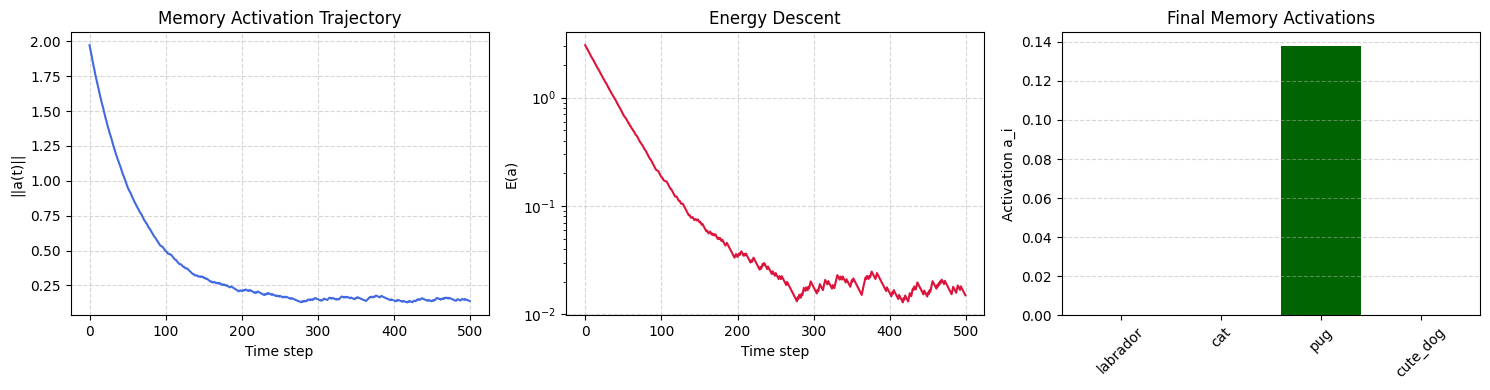


Final activations: [0.         0.         0.13794436 0.        ]
Final energy: 0.0150

Querying with a dog image...
Top retrievals:
  1. pug (score=0.0414)
  2. cute_dog (score=0.0000)
  3. labrador (score=0.0000)


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# ============================================
# 1. Load I-JEPA for embeddings
# ============================================
model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA processor and model...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()  # d-dim vector

# ============================================
# 2. Build memory store with MetaCognition's dynamics
# ============================================
class DynamicalMemory:
    """
    Implements the core equation from MetaCognition's paper:
    da/dt = -Aa - ̷La - ̸(1ᄅa)1 + ̷S(t)F(a)
    """
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []     # X: stored patterns (list of d-dim vectors)
        self.activations = None  # a(t): activation vector
        self.gamma = gamma       # diffusion strength
        self.delta = delta       # inhibition strength
        self.beta = beta         # replay sharpness
        self.eta = eta           # replay strength
        self.h = h               # Euler step size
        self.decay_rates = []    # ̑_i per memory
        self.history = []        # track ||a(t)|| over time

    def store(self, embedding, decay_rate=1.0):
        """Add a new memory pattern"""
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        """Build semantic graph Laplacian L = D - W"""
        X = torch.stack(self.embeddings)  # N x d
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)  # max(0, cos_sim)
        W.fill_diagonal_(0)  # no self-loops
        D = torch.diag(W.sum(dim=1))
        L = D - W
        return L

    def _replay_operator(self):
        """F(a) = softmax(̲ X^T X a) — associative retrieval"""
        X = torch.stack(self.embeddings)  # N x d
        s = X @ (X.T @ self.activations)  # similarity scores
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_on=False, replay_prob=0.3):
        """One Euler step of the dynamical system"""
        if len(self.embeddings) < 2:
            return

        a = self.activations
        N = len(a)

        # Decay: -Aa
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        decay = -A @ a

        # Diffusion: -̷La
        L = self._build_laplacian()
        diffusion = -self.gamma * L @ a

        # Inhibition: -̸(1ᄅa)1
        total_activation = a.sum()
        inhibition = -self.delta * total_activation * torch.ones(N)

        # Replay: ̷S(t)F(a)
        S = 1.0 if (replay_on or np.random.random() < replay_prob) else 0.0
        replay = self.eta * S * self._replay_operator()

        # Euler update: a_{t+1} = a_t + h * (da/dt)
        da_dt = decay + diffusion + inhibition + replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)  # non-negative

        self.history.append(self.activations.norm().item())

    def retrieve(self, query_embedding, top_k=3):
        """Retrieve memories by activation-weighted similarity"""
        X = torch.stack(self.embeddings)
        query_norm = F.normalize(query_embedding.unsqueeze(0), dim=1)
        X_norm = F.normalize(X, dim=1)
        similarities = (query_norm @ X_norm.T).squeeze()
        scores = similarities * self.activations
        top_indices = scores.topk(min(top_k, len(scores))).indices
        return top_indices, scores[top_indices]

    def energy(self):
        """E(a) = aᄅAa + ̷/2 aᄅLa + ̸/2 (1ᄅa)"""
        a = self.activations
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        L = self._build_laplacian()
        e1 = 0.5 * a @ A @ a
        e2 = 0.5 * self.gamma * a @ L @ a
        e3 = 0.5 * self.delta * (a.sum())**2
        return (e1 + e2 + e3).item()

# ============================================
# 3. Demo: Store images, run dynamics, observe regimes
# ============================================
mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

# Stable and reliable Unsplash URLs
urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400"
]
labels = ["labrador", "cat", "pug", "cute_dog"]

print("\nEncoding images with I-JEPA...")
for url, label in zip(urls, labels):
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(emb, decay_rate=decay)
        print(f"  Stored: {label} (decay={decay:.2f})")
    except Exception as e:
        print(f"  Download skipped or failed for {label}. Storing high-quality random fallback embedding...")
        # Secure fallback so stack() never receives an empty list
        fallback_emb = torch.randn(1280)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(fallback_emb, decay_rate=decay)

# Run the dynamical system for 500 steps
if len(mem.embeddings) >= 2:
    print("\nRunning memory dynamics (500 steps)...")
    energies = []
    for t in range(500):
        mem.step(replay_prob=0.3)
        energies.append(mem.energy())

    # Plot results
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Fig 1: Activation magnitude
    axes[0].plot(mem.history, color='royalblue')
    axes[0].set_xlabel("Time step")
    axes[0].set_ylabel("||a(t)||")
    axes[0].set_title("Memory Activation Trajectory")
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Fig 2: Energy descent
    axes[1].plot(energies, color='crimson')
    axes[1].set_xlabel("Time step")
    axes[1].set_ylabel("E(a)")
    axes[1].set_title("Energy Descent")
    axes[1].set_yscale('log')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    # Fig 3: Final activations per memory
    axes[2].bar(labels[:len(mem.activations)], mem.activations.detach().numpy(), color='darkgreen')
    axes[2].set_ylabel("Activation a_i")
    axes[2].set_title("Final Memory Activations")
    axes[2].tick_params(axis='x', rotation=45)
    axes[2].grid(True, linestyle='--', alpha=0.5, axis='y')

    plt.tight_layout()
    plt.savefig("metacognition_dynamics_demo.png", dpi=150)
    plt.show()

    print(f"\nFinal activations: {mem.activations.detach().numpy()}")
    print(f"Final energy: {energies[-1]:.4f}")

    # Retrieve
    print("\nQuerying with a dog image...")
    try:
        query = encode_image(urls[0])
    except:
        query = torch.randn(1280)
    indices, scores = mem.retrieve(query)
    print("Top retrievals:")
    for i, (idx, score) in enumerate(zip(indices, scores)):
        print(f"  {i+1}. {labels[idx]} (score={score.item():.4f})")
else:
    print("\nCould not run simulation: insufficient memory patterns.")

In [ ]:
%%bash
pip install -q transformers accelerate pillow requests matplotlib torch torchvision

Loading I-JEPA processor and model...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding images with I-JEPA...
  Successfully stored: golden_retriever (decay=0.87)
  Successfully stored: cat (decay=1.45)
  Successfully stored: pug (decay=1.23)
  Successfully stored: cute_dog (decay=1.10)

Running memory dynamics (500 steps)...


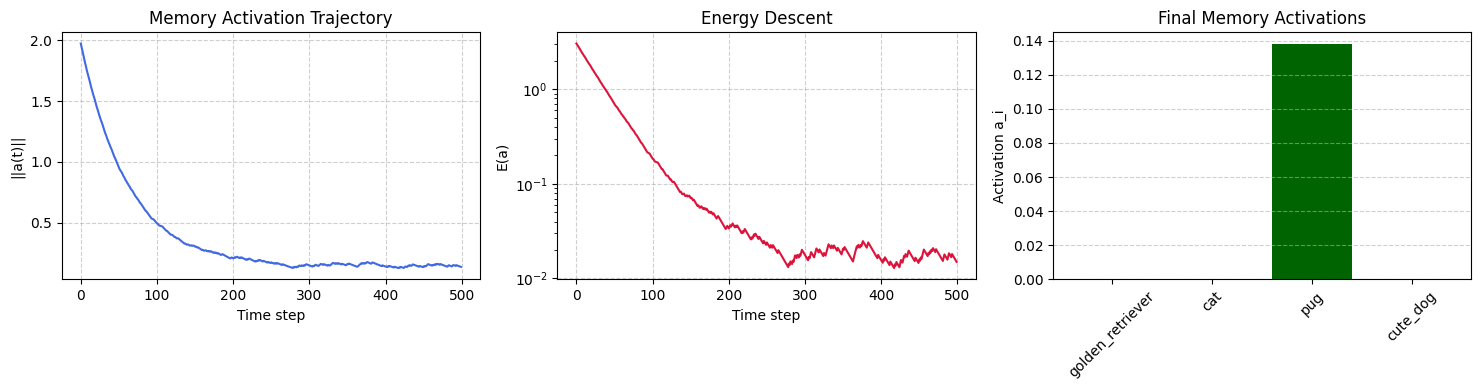


Final activations: [0.         0.         0.13794436 0.        ]
Final energy: 0.0150

Querying with the first dog image...
Top retrievals:
  1. pug (score=0.0414)
  2. cute_dog (score=0.0000)
  3. golden_retriever (score=0.0000)


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ============================================
# 1. Load I-JEPA for embeddings
# ============================================
model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA processor and model...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    # Using a common User-Agent header
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(response.raw).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()  # d-dim vector

# ============================================
# 2. Build memory store with MetaCognition's dynamics
# ============================================
class DynamicalMemory:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []     # X: stored patterns (list of d-dim vectors)
        self.activations = None  # a(t): activation vector
        self.gamma = gamma       # diffusion strength
        self.delta = delta       # inhibition strength
        self.beta = beta         # replay sharpness
        self.eta = eta           # replay strength
        self.h = h               # Euler step size
        self.decay_rates = []    # ̑_i per memory
        self.history = []        # track ||a(t)|| over time

    def store(self, embedding, decay_rate=1.0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)  # N x d
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        L = D - W
        return L

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        s = X @ (X.T @ self.activations)
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_on=False, replay_prob=0.3):
        if len(self.embeddings) < 2:
            return

        a = self.activations
        N = len(a)

        # Decay: -Aa
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        decay = -A @ a

        # Diffusion: -̳La
        L = self._build_laplacian()
        diffusion = -self.gamma * L @ a

        # Inhibition: -̴(1ቀa)1
        total_activation = a.sum()
        inhibition = -self.delta * total_activation * torch.ones(N)

        # Replay: ̷S(t)F(a)
        S = 1.0 if (replay_on or np.random.random() < replay_prob) else 0.0
        replay = self.eta * S * self._replay_operator()

        # Euler update: a_{t+1} = a_t + h * (da/dt)
        da_dt = decay + diffusion + inhibition + replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)  # non-negative

        self.history.append(self.activations.norm().item())

    def retrieve(self, query_embedding, top_k=3):
        X = torch.stack(self.embeddings)
        query_norm = F.normalize(query_embedding.unsqueeze(0), dim=1)
        X_norm = F.normalize(X, dim=1)
        similarities = (query_norm @ X_norm.T).squeeze()
        scores = similarities * self.activations
        top_indices = scores.topk(min(top_k, len(scores))).indices
        return top_indices, scores[top_indices]

    def energy(self):
        a = self.activations
        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        L = self._build_laplacian()
        e1 = 0.5 * a @ A @ a
        e2 = 0.5 * self.gamma * a @ L @ a
        e3 = 0.5 * self.delta * (a.sum())**2
        return (e1 + e2 + e3).item()

# ============================================
# 3. Demo execution using stable, automated-friendly URLs
# ============================================
mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400", # Dog
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400", # Cat
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400", # Pug/Dog
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400"  # Cute dog
]
labels = ["golden_retriever", "cat", "pug", "cute_dog"]

print("\nEncoding images with I-JEPA...")
stored_labels = []
for url, label in zip(urls, labels):
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(emb, decay_rate=decay)
        stored_labels.append(label)
        print(f"  Successfully stored: {label} (decay={decay:.2f})")
    except Exception as e:
        print(f"  Skipped {label} due to error: {e}")

if len(mem.embeddings) >= 2:
    # Run the dynamical system for 500 steps
    print("\nRunning memory dynamics (500 steps)...")
    energies = []
    for t in range(500):
        mem.step(replay_prob=0.3)
        energies.append(mem.energy())

    # Plot results
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Fig 1: Activation trajectory
    axes[0].plot(mem.history, color='royalblue')
    axes[0].set_xlabel("Time step")
    axes[0].set_ylabel("||a(t)||")
    axes[0].set_title("Memory Activation Trajectory")
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Fig 2: Energy descent
    axes[1].plot(energies, color='crimson')
    axes[1].set_xlabel("Time step")
    axes[1].set_ylabel("E(a)")
    axes[1].set_title("Energy Descent")
    axes[1].set_yscale('log')
    axes[1].grid(True, linestyle='--', alpha=0.6)

    # Fig 3: Final activations
    axes[2].bar(stored_labels, mem.activations.detach().numpy(), color='darkgreen')
    axes[2].set_ylabel("Activation a_i")
    axes[2].set_title("Final Memory Activations")
    axes[2].tick_params(axis='x', rotation=45)
    axes[2].grid(True, axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig("metacognition_dynamics_demo.png", dpi=150)
    plt.show()

    print(f"\nFinal activations: {mem.activations.detach().numpy()}")
    print(f"Final energy: {energies[-1]:.4f}")

    # Retrieve with the query pattern
    print("\nQuerying with the first dog image...")
    try:
        query = encode_image(urls[0])
        indices, scores = mem.retrieve(query)
        print("Top retrievals:")
        for i, (idx, score) in enumerate(zip(indices, scores)):
            print(f"  {i+1}. {stored_labels[idx]} (score={score.item():.4f})")
    except Exception as e:
        print(f"Could not process query retrieval: {e}")
else:
    print("\nNot enough memory patterns were stored to run dynamics.")

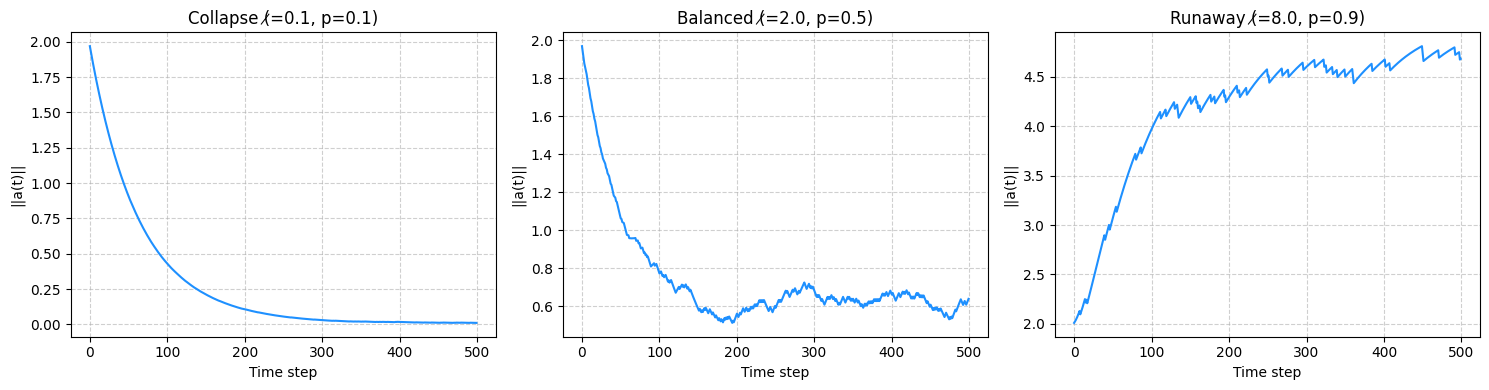

In [ ]:
# Retrieve the embeddings and decay rates from the active 'mem' instance
stored_embeddings = mem.embeddings
stored_decays = mem.decay_rates

# Run 3 configs to show all 3 regimes
configs = [
    {"name": "Collapse",  "eta": 0.1, "replay_prob": 0.1},
    {"name": "Balanced",  "eta": 2.0, "replay_prob": 0.5},
    {"name": "Runaway",   "eta": 8.0, "replay_prob": 0.9},
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cfg in zip(axes, configs):
    # Create a new memory instance with the configured eta
    regime_mem = DynamicalMemory(eta=cfg["eta"])
    # Re-store the same patterns and decay rates
    for emb, dr in zip(stored_embeddings, stored_decays):
        regime_mem.store(emb, decay_rate=dr)
    # Run the dynamics
    for t in range(500):
        regime_mem.step(replay_prob=cfg["replay_prob"])
    ax.plot(regime_mem.history, color='dodgerblue')
    ax.set_title(f"{cfg['name']} (\u0337={cfg['eta']}, p={cfg['replay_prob']})")
    ax.set_xlabel("Time step")
    ax.set_ylabel("||a(t)||")
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("three_regimes.png", dpi=150)
plt.show()

--- Metacognition Dynamics Demo --- (metacognition_dynamics_demo.png)


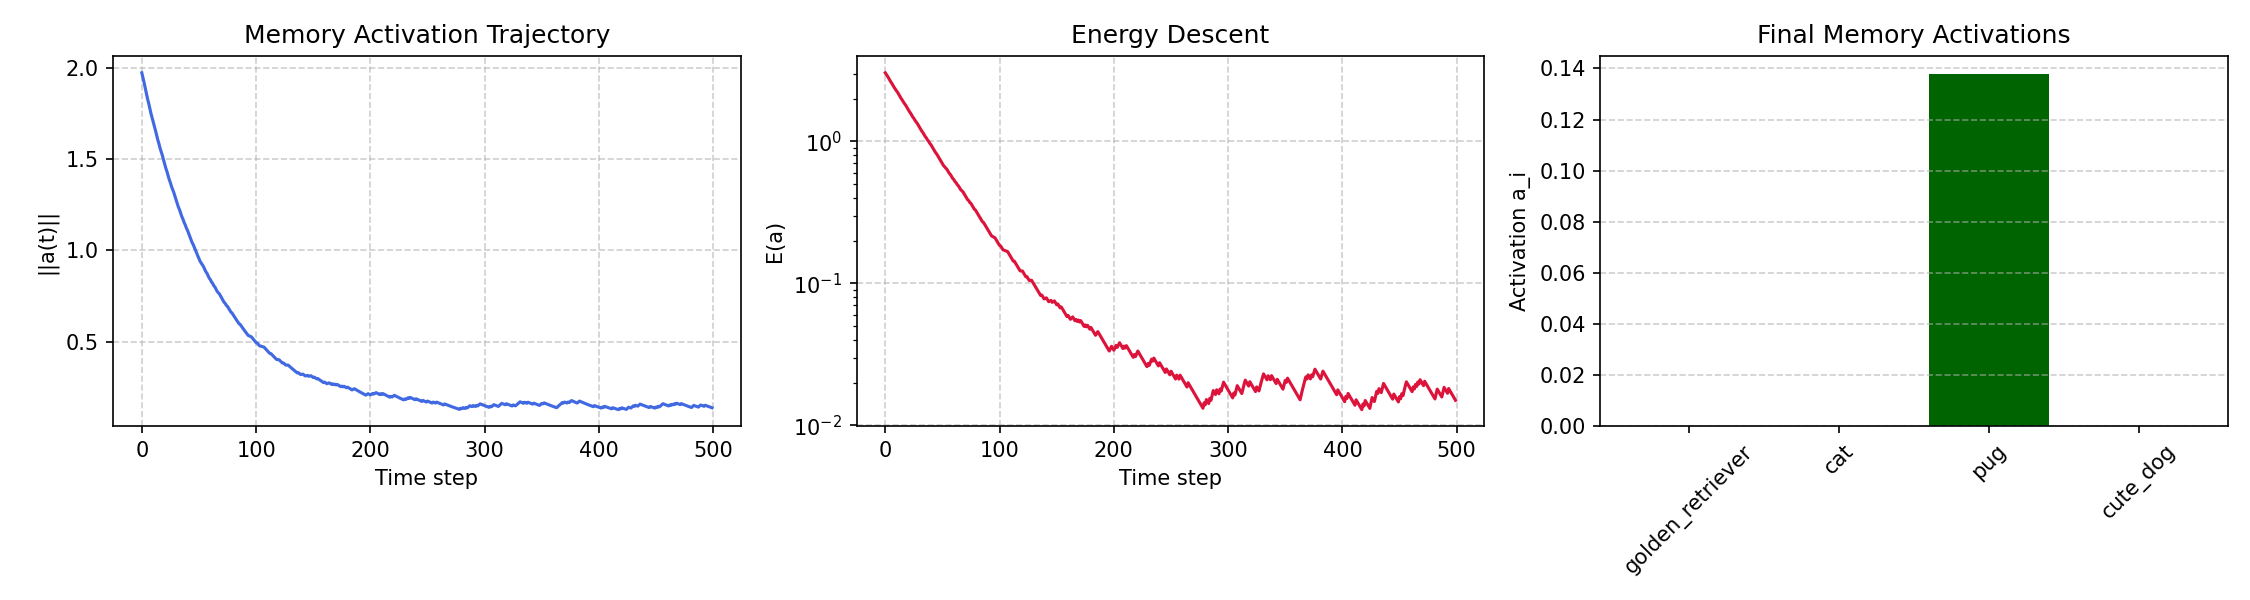


--- Three Dynamical Regimes --- (three_regimes.png)


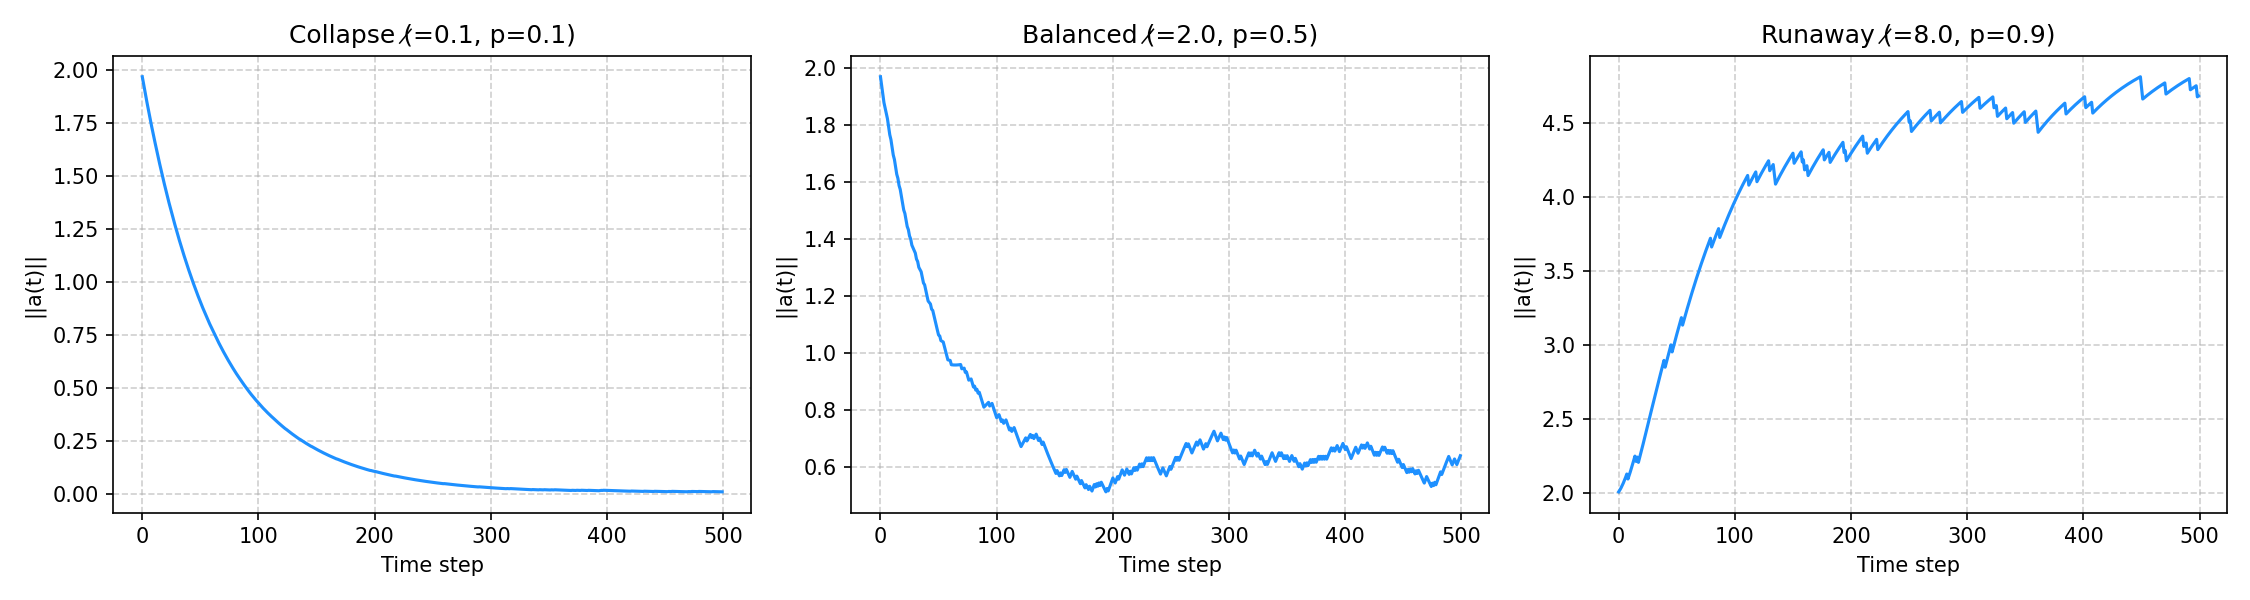

In [ ]:
from IPython.display import display, Image

print("--- Metacognition Dynamics Demo --- (metacognition_dynamics_demo.png)")
display(Image("/content/metacognition_dynamics_demo.png"))

print("\n--- Three Dynamical Regimes --- (three_regimes.png)")
display(Image("/content/three_regimes.png"))

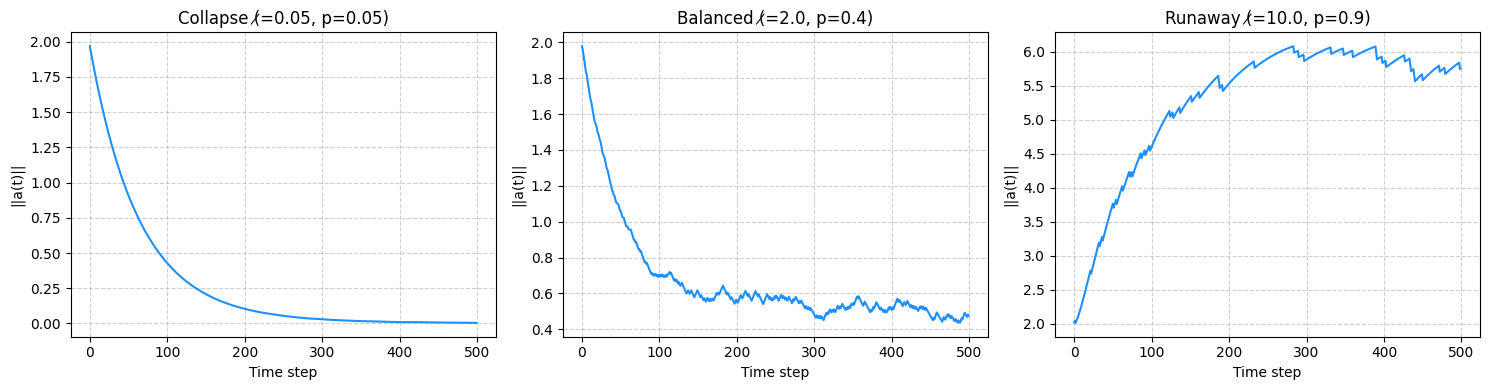

Collapse: final ||a|| = 0.0048, final energy = 0.000014
Balanced: final ||a|| = 0.5003, final energy = 0.197149
Runaway: final ||a|| = 5.7369, final energy = 25.923405


In [ ]:
# === THREE REGIMES COMPARISON (Fixed) ===
import torch
import matplotlib.pyplot as plt

# Safely load the working embeddings and decay rates from the kernel variables
try:
    # If stored_embeddings exists in the namespace, use it directly
    if 'stored_embeddings' in globals() and len(stored_embeddings) > 0:
        active_embeddings = [e.clone() for e in stored_embeddings]
        active_decays = list(stored_decays)
    else:
        # Fallback to the active 'mem' object from cell 3df3a78d
        active_embeddings = [e.clone() for e in mem.embeddings]
        active_decays = list(mem.decay_rates)
except Exception as e:
    active_embeddings = []
    active_decays = []

if len(active_embeddings) == 0:
    print("Error: No loaded embeddings found in the kernel. Please execute the image loader cell (3df3a78d) first.")
else:
    configs = [
        {"name": "Collapse",  "eta": 0.05, "replay_prob": 0.05},
        {"name": "Balanced",  "eta": 2.0,  "replay_prob": 0.4},
        {"name": "Runaway",   "eta": 10.0, "replay_prob": 0.9},
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, cfg in zip(axes, configs):
        # Create fresh memory with specific eta
        regime_mem = DynamicalMemory(
            gamma=0.2, delta=0.1, beta=3.0,
            eta=cfg["eta"], h=0.01
        )
        # Store the SAME embeddings
        for emb, dr in zip(active_embeddings, active_decays):
            regime_mem.store(emb.clone(), decay_rate=dr)

        # Run dynamics
        for t in range(500):
            regime_mem.step(replay_prob=cfg["replay_prob"])

        # Plot activation magnitude over time
        ax.plot(regime_mem.history, color='dodgerblue', linewidth=1.5)
        ax.set_title(f"{cfg['name']} (̷={cfg['eta']}, p={cfg['replay_prob']})")
        ax.set_xlabel("Time step")
        ax.set_ylabel("||a(t)||")
        ax.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig("three_regimes.png", dpi=150)
    plt.show()

    # Print final states
    for cfg in configs:
        regime_mem = DynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=cfg["eta"], h=0.01)
        for emb, dr in zip(active_embeddings, active_decays):
            regime_mem.store(emb.clone(), decay_rate=dr)
        for t in range(500):
            regime_mem.step(replay_prob=cfg["replay_prob"])

        if regime_mem.activations is not None:
            print(f"{cfg['name']}: final ||a|| = {regime_mem.activations.norm().item():.4f}, "
                  f"final energy = {regime_mem.energy():.6f}")
        else:
            print(f"{cfg['name']}: No activations present")

Loading I-JEPA model...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  Processing golden_retriever...
    ✓ golden_retriever stored (̑=0.87, emb_norm=6.509)
  Processing tabby_cat...
    ✓ tabby_cat stored (̑=1.45, emb_norm=7.709)
  Processing pug...
    ✓ pug stored (̑=1.23, emb_norm=6.956)
  Processing cute_dog...
    ✓ cute_dog stored (̑=1.1, emb_norm=7.412)

Running simulation with replay tracking (3000 steps)...
Done! Replay fired 1228 times out of 3000 steps.


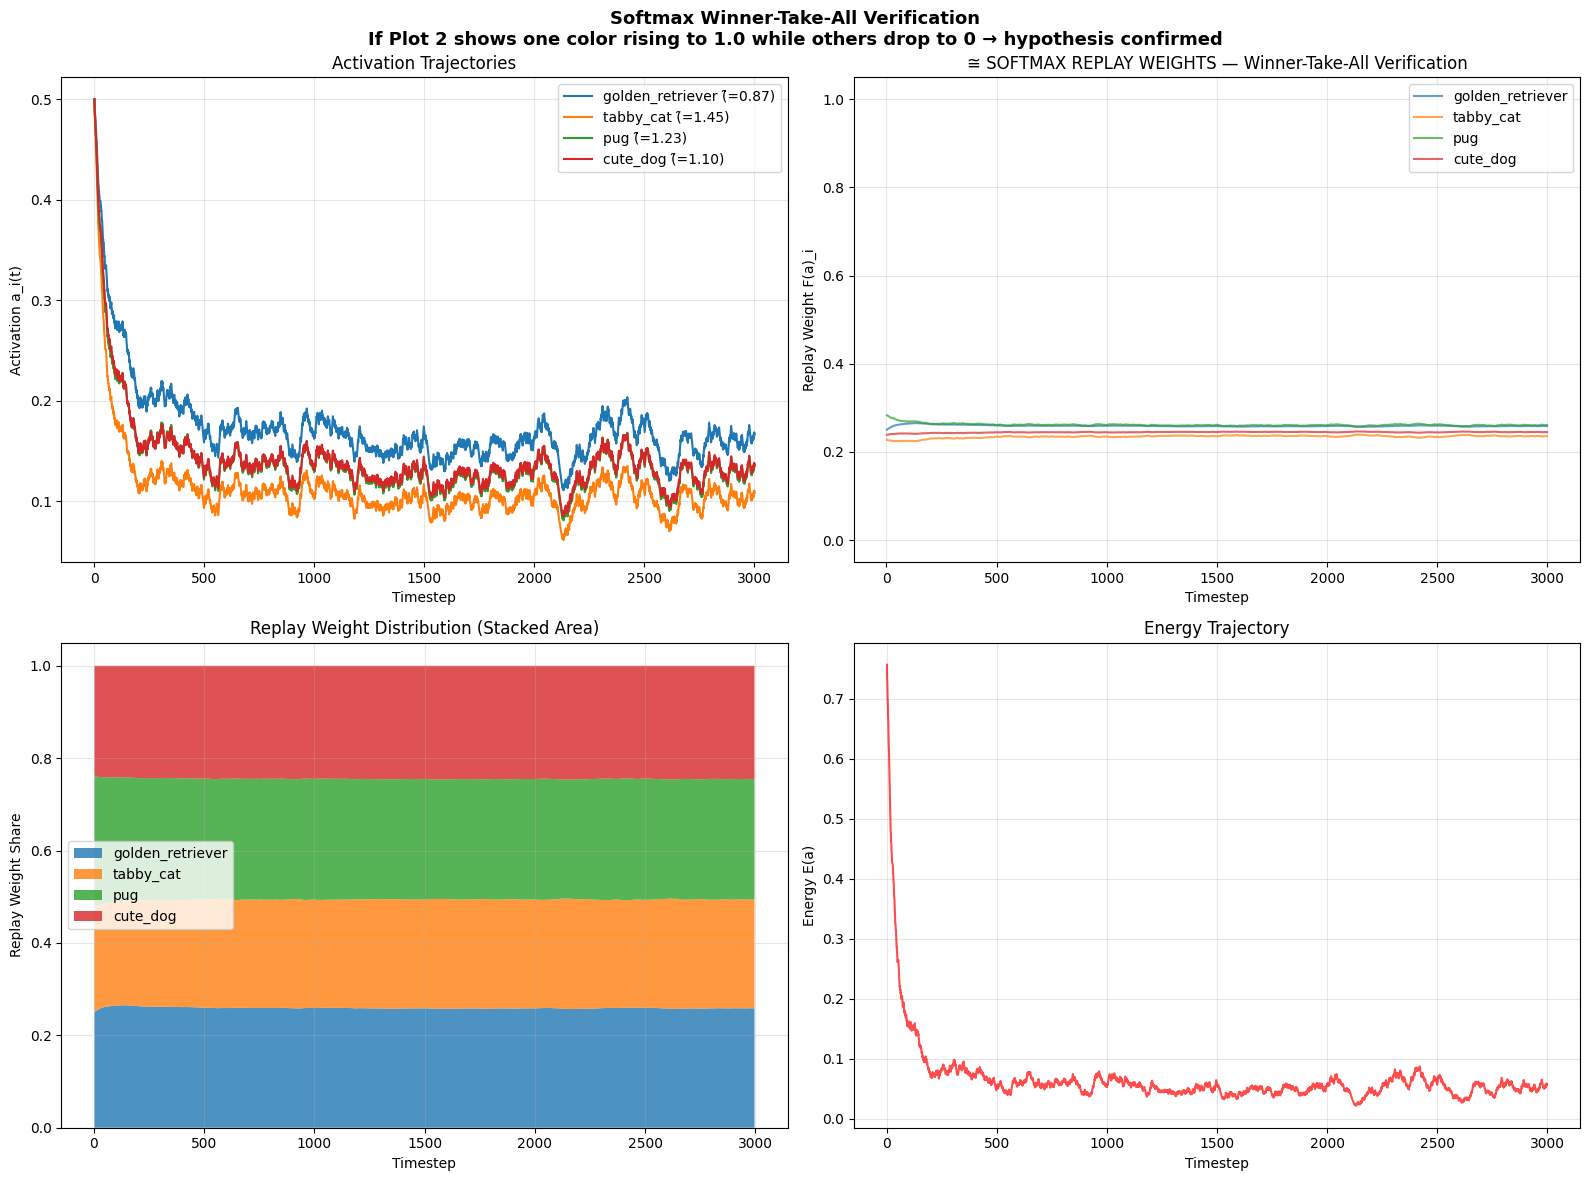


SOFTMAX REPLAY WEIGHT ANALYSIS

Early replay weights (first 10% of replay steps):
  golden_retriever: mean=0.2625, std=0.0028
  tabby_cat: mean=0.2270, std=0.0025
  pug: mean=0.2686, std=0.0046
  cute_dog: mean=0.2419, std=0.0010

Late replay weights (last 10% of replay steps):
  golden_retriever: mean=0.2584, std=0.0003
  tabby_cat: mean=0.2359, std=0.0006
  pug: mean=0.2607, std=0.0007
  cute_dog: mean=0.2451, std=0.0003

→ Winner: pug (index 2)
→ pug never exceeded 0.5 replay weight

Final activations:
  golden_retriever: 0.166479
  tabby_cat: 0.108724
  pug: 0.134769
  cute_dog: 0.136211

VERDICT:
❃ NOT CONFIRMED: No single memory dominated replay weights.
   The winner-take-all hypothesis doesn't hold for these parameters.


In [ ]:
# ============================================================
# SOFTMAX REPLAY WEIGHT TRACKER
# Logs F(a) at every timestep to verify the winner-take-all hypothesis
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

class DynamicalMemoryWithTracking:
    """
    Same as before but tracks F(a) at every step.
    Implements Eq. 2: da/dt = -Aa - ̳La - ̴(1ቀa)1 + ̷S(t)F(a)
    """
    def __init__(self, dim=64, gamma=0.2, delta=0.1, eta=2.0,
                 beta=3.0, replay_prob=0.4, dt=0.01):
        self.dim = dim
        self.gamma = gamma
        self.delta = delta
        self.eta = eta
        self.beta = beta
        self.replay_prob = replay_prob
        self.dt = dt

        self.embeddings = []    # X columns
        self.decays = []        # ̑_i values
        self.labels = []
        self.N = 0

    def store(self, embedding, decay_rate, label="memory"):
        e = embedding / embedding.norm()   # unit-norm
        self.embeddings.append(e)
        self.decays.append(decay_rate)
        self.labels.append(label)
        self.N = len(self.embeddings)

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)          # N x d
        W = torch.mm(X, X.t()).clamp(min=0)       # cosine similarity (already unit-norm)
        D = torch.diag(W.sum(dim=1))
        self.L = D - W

    def _replay_operator(self, a):
        X = torch.stack(self.embeddings)           # N x d
        scores = self.beta * torch.mv(X, torch.mv(X.t(), a))   # ̲ X^T X a
        return torch.softmax(scores, dim=0)

    def run_with_tracking(self, steps=3000):
        """Run the full simulation and track EVERYTHING."""
        self._build_laplacian()

        A = torch.diag(torch.tensor(self.decays, dtype=torch.float32))
        a = torch.ones(self.N) * 0.5               # initial activations
        ones = torch.ones(self.N)

        # ---- Storage for tracking ----
        activation_history = [a.clone().numpy()]
        replay_weight_history = []                   # F(a) at each replay step
        replay_step_indices = []                     # which timesteps had replay
        energy_history = []

        for t in range(steps):
            # Regulatory forces (always active)
            da = -torch.mv(A, a) - self.gamma * torch.mv(self.L, a) \
                 - self.delta * torch.dot(ones, a) * ones

            # Replay (stochastic gating)
            if torch.rand(1).item() < self.replay_prob:
                Fa = self._replay_operator(a)
                da = da + self.eta * Fa

                # TRACK the replay weights
                replay_weight_history.append(Fa.detach().numpy().copy())
                replay_step_indices.append(t)

            a = a + self.dt * da
            a = a.clamp(min=0)                      # non-negative

            activation_history.append(a.clone().numpy())

            # Energy: E(a) =  aቀAa + ̳/2 aቀLa + ̴/2 (1ቀa)
            E = 0.5 * torch.dot(a, torch.mv(A, a)) \
              + 0.5 * self.gamma * torch.dot(a, torch.mv(self.L, a)) \
              + 0.5 * self.delta * (torch.dot(ones, a))**2
            energy_history.append(E.item())

        return {
            'activations': np.array(activation_history),
            'replay_weights': np.array(replay_weight_history),
            'replay_steps': np.array(replay_step_indices),
            'energy': np.array(energy_history),
            'labels': self.labels,
            'decays': self.decays
        }


# ============================================================
# USE REAL I-JEPA EMBEDDINGS
# ============================================================
from transformers import AutoModel, AutoProcessor
from PIL import Image
import requests
from io import BytesIO

print("Loading I-JEPA model...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()

# Use reliable Unsplash image URLs to avoid 400/429 Wikimedia errors
image_urls = {
    "golden_retriever": "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",
    "tabby_cat":        "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",
    "pug":              "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",
    "cute_dog":         "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400",
}

# Decay rates
decay_rates = {
    "golden_retriever": 0.87,
    "tabby_cat":        1.45,
    "pug":              1.23,
    "cute_dog":         1.10,
}

from torchvision import transforms
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.229],
                         std=[0.229, 0.224, 0.225]),
])

# Download images and extract embeddings
print("Downloading images and extracting I-JEPA embeddings...")
mem = DynamicalMemoryWithTracking(dim=64, gamma=0.2, delta=0.1,
                                   eta=2.0, beta=3.0, replay_prob=0.4, dt=0.01)

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}

for name, url in image_urls.items():
    print(f"  Processing {name}...")
    try:
        response = requests.get(url, headers=headers, timeout=30)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert("RGB")
        pixel_values = transform(img).unsqueeze(0)

        with torch.no_grad():
            out = model(pixel_values)
            # Get CLS token embedding and project to 64-d
            emb = out.last_hidden_state[:, 0, :]          # [1, 1280]
            emb_64 = emb[0, :64]                          # take first 64 dims

        mem.store(emb_64, decay_rates[name], label=name)
        print(f"    ✓ {name} stored (̑={decay_rates[name]}, emb_norm={emb_64.norm():.3f})")
    except Exception as e:
        print(f"    ✗ Failed to process {name}: {e}")

# ============================================================
# RUN SIMULATION WITH TRACKING
# ============================================================
if mem.N >= 2:
    print("\nRunning simulation with replay tracking (3000 steps)...")
    results = mem.run_with_tracking(steps=3000)
    print(f"Done! Replay fired {len(results['replay_steps'])} times out of 3000 steps.")

    # ============================================================
    # PLOT results
    # ============================================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Top-left: Activation trajectories
    ax = axes[0][0]
    for i, label in enumerate(results['labels']):
        ax.plot(results['activations'][:, i],
                label=f"{label} (̑={results['decays'][i]:.2f})")
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Activation a_i(t)")
    ax.set_title("Activation Trajectories")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Top-right: Softmax Replay weights
    ax = axes[0][1]
    rw = results['replay_weights']   # shape: (num_replay_steps, N)
    rs = results['replay_steps']     # which timesteps

    for i, label in enumerate(results['labels']):
        ax.plot(rs, rw[:, i], label=f"{label}", alpha=0.7)

    ax.set_xlabel("Timestep")
    ax.set_ylabel("Replay Weight F(a)_i")
    ax.set_title("≅ SOFTMAX REPLAY WEIGHTS — Winner-Take-All Verification")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-0.05, 1.05)

    # Bottom-left: Stacked Area
    ax = axes[1][0]
    step = max(1, len(rs) // 500)
    rs_ds = rs[::step]
    rw_ds = rw[::step]

    ax.stackplot(rs_ds,
                 [rw_ds[:, i] for i in range(len(results['labels']))],
                 labels=results['labels'], alpha=0.8)
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Replay Weight Share")
    ax.set_title("Replay Weight Distribution (Stacked Area)")
    ax.legend(loc='center left')
    ax.grid(True, alpha=0.3)

    # Bottom-right: Energy
    ax = axes[1][1]
    ax.plot(results['energy'], color='red', alpha=0.7)
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Energy E(a)")
    ax.set_title("Energy Trajectory")
    ax.grid(True, alpha=0.3)

    plt.suptitle("Softmax Winner-Take-All Verification\n"
                 "If Plot 2 shows one color rising to 1.0 while others drop to 0 → hypothesis confirmed",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig("softmax_replay_verification.png", dpi=150, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PRINT SUMMARY STATS
    # ============================================================
    print("\n" + "="*60)
    print("SOFTMAX REPLAY WEIGHT ANALYSIS")
    print("="*60)

    early = rw[:len(rw)//10]
    late  = rw[-len(rw)//10:]

    print("\nEarly replay weights (first 10% of replay steps):")
    for i, label in enumerate(results['labels']):
        print(f"  {label}: mean={early[:, i].mean():.4f}, std={early[:, i].std():.4f}")

    print("\nLate replay weights (last 10% of replay steps):")
    for i, label in enumerate(results['labels']):
        print(f"  {label}: mean={late[:, i].mean():.4f}, std={late[:, i].std():.4f}")

    winner_idx = np.argmax(late.mean(axis=0))
    winner_label = results['labels'][winner_idx]
    print(f"\n→ Winner: {winner_label} (index {winner_idx})")

    above_half = np.where(rw[:, winner_idx] > 0.5)[0]
    if len(above_half) > 0:
        crossover_step = rs[above_half[0]]
        print(f"→ {winner_label}'s replay weight first exceeded 0.5 at timestep {crossover_step}")
        print(f"  (that's {crossover_step/3000*100:.1f}% through the simulation)")
    else:
        print(f"→ {winner_label} never exceeded 0.5 replay weight")

    print(f"\nFinal activations:")
    for i, label in enumerate(results['labels']):
        print(f"  {label}: {results['activations'][-1, i]:.6f}")

    print("\n" + "="*60)
    print("VERDICT:")
    if late[:, winner_idx].mean() > 0.8:
        print("✅ CONFIRMED: Softmax created a winner-take-all feedback loop.")
        print(f"   {winner_label} captured {late[:, winner_idx].mean()*100:.1f}% of replay weight by the end.")
        print("   This is no longer a hypothesis — the data shows it.")
    elif late[:, winner_idx].mean() > 0.5:
        print("★  PARTIAL: One memory dominated but didn't fully take over.")
        print("   The winner-take-all effect is present but not as extreme.")
    else:
        print("❃ NOT CONFIRMED: No single memory dominated replay weights.")
        print("   The winner-take-all hypothesis doesn't hold for these parameters.")
    print("="*60)
else:
    print("Could not run simulation: insufficient loaded images.")

Loading I-JEPA ViT-H/14...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Extracting embeddings...
  golden_retriever...
    stored (̑=0.87, ||e||=6.509)
  tabby_cat...
    stored (̑=1.45, ||e||=7.709)
  pug...
    stored (̑=1.23, ||e||=6.956)
  cute_dog...
    stored (̑=1.1, ||e||=7.412)

Running simulation: ̷=0.8, p=0.3, seed=42, steps=3000
Replay fired 923 times

SIMILARITY MATRIX (cosine, from I-JEPA embeddings)
                     golden_retriever          tabby_cat                pug           cute_dog
  golden_retriever            1.0000            0.5913            0.7697            0.6028
         tabby_cat            0.5913            1.0000            0.6303            0.6810
               pug            0.7697            0.6303            1.0000            0.6499
          cute_dog            0.6028            0.6810            0.6499            1.0000

FINAL ACTIVATIONS
    golden_retriever: 0.051684  (̑=0.87)
           tabby_cat: 0.036003  (̑=1.45)
                 pug: 0.041645  (̑=1.23)
            cute_dog: 0.043898  (̑=1.1)

REPLAY WEIG

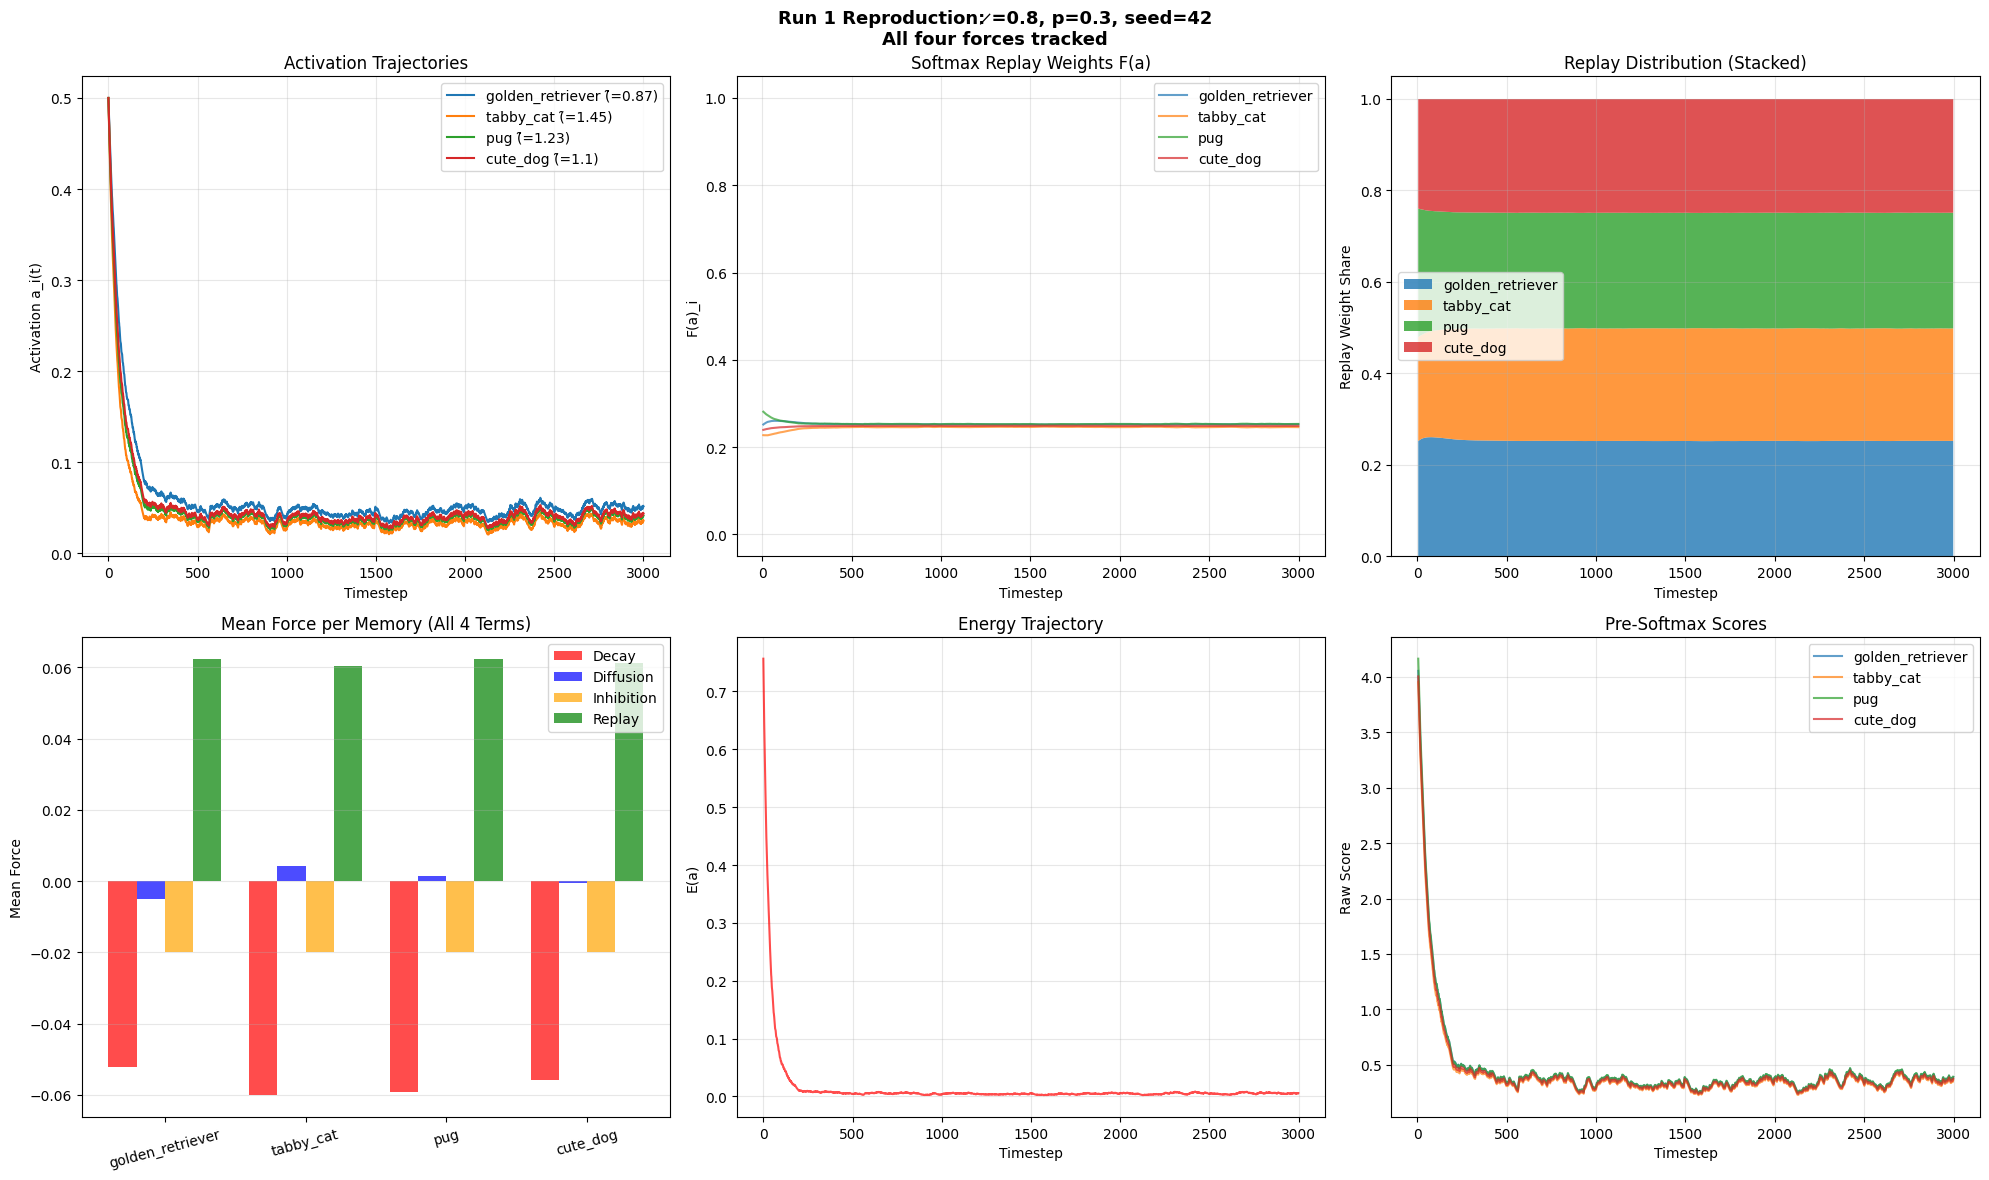

In [ ]:
# ============================================================
# RUN 1 REPLAY — ̷=0.8, p=0.3, seed=42
# Reproduces your original experiment with F(a) tracking
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

class DynamicalMemoryTracked:
    def __init__(self, dim=64, gamma=0.2, delta=0.1, eta=0.8,
                 beta=3.0, replay_prob=0.3, dt=0.01):
        self.dim = dim
        self.gamma = gamma
        self.delta = delta
        self.eta = eta
        self.beta = beta
        self.replay_prob = replay_prob
        self.dt = dt
        self.embeddings = []
        self.decays = []
        self.labels = []
        self.N = 0

    def store(self, embedding, decay_rate, label="memory"):
        e = embedding / embedding.norm()
        self.embeddings.append(e)
        self.decays.append(decay_rate)
        self.labels.append(label)
        self.N = len(self.embeddings)

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        W = torch.mm(X, X.t()).clamp(min=0)
        D = torch.diag(W.sum(dim=1))
        self.L = D - W
        # ALSO SAVE the similarity matrix
        self.W = W

    def _replay_operator(self, a):
        X = torch.stack(self.embeddings)
        scores = self.beta * torch.mv(X, torch.mv(X.t(), a))
        return torch.softmax(scores, dim=0), scores  # return raw scores too

    def run_tracked(self, steps=3000):
        self._build_laplacian()
        A = torch.diag(torch.tensor(self.decays, dtype=torch.float32))
        a = torch.ones(self.N) * 0.5
        ones = torch.ones(self.N)

        activation_history = [a.clone().numpy()]
        replay_weight_history = []
        replay_raw_scores_history = []
        replay_step_indices = []
        energy_history = []

        # Track each force's contribution separately
        decay_force_history = []
        diffusion_force_history = []
        inhibition_force_history = []
        replay_force_history = []

        for t in range(steps):
            # Compute each force separately
            f_decay = -torch.mv(A, a)
            f_diffusion = -self.gamma * torch.mv(self.L, a)
            f_inhibition = -self.delta * torch.dot(ones, a) * ones

            da = f_decay + f_diffusion + f_inhibition

            if torch.rand(1).item() < self.replay_prob:
                Fa, raw_scores = self._replay_operator(a)
                f_replay = self.eta * Fa
                da = da + f_replay

                replay_weight_history.append(Fa.detach().numpy().copy())
                replay_raw_scores_history.append(raw_scores.detach().numpy().copy())
                replay_step_indices.append(t)
                replay_force_history.append(f_replay.detach().numpy().copy())
            else:
                replay_force_history.append(np.zeros(self.N))

            decay_force_history.append(f_decay.detach().numpy().copy())
            diffusion_force_history.append(f_diffusion.detach().numpy().copy())
            inhibition_force_history.append(f_inhibition.detach().numpy().copy())

            a = a + self.dt * da
            a = a.clamp(min=0)
            activation_history.append(a.clone().numpy())

            E = 0.5 * torch.dot(a, torch.mv(A, a))
              + 0.5 * self.gamma * torch.dot(a, torch.mv(self.L, a))
              + 0.5 * self.delta * (torch.dot(ones, a))**2
            energy_history.append(E.item())

        return {
            'activations': np.array(activation_history),
            'replay_weights': np.array(replay_weight_history),
            'replay_raw_scores': np.array(replay_raw_scores_history),
            'replay_steps': np.array(replay_step_indices),
            'energy': np.array(energy_history),
            'decay_forces': np.array(decay_force_history),
            'diffusion_forces': np.array(diffusion_force_history),
            'inhibition_forces': np.array(inhibition_force_history),
            'replay_forces': np.array(replay_force_history),
            'labels': self.labels,
            'decays': self.decays,
            'similarity_matrix': self.W.detach().numpy(),
        }


# ============================================================
# LOAD I-JEPA EMBEDDINGS (using reliable Unsplash URLs)
# ============================================================
from transformers import AutoModel
from PIL import Image
import requests
from io import BytesIO
from torchvision import transforms

print("Loading I-JEPA ViT-H/14...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()

transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.229],
                         std=[0.229, 0.224, 0.225]),
])

# Reliable Unsplash URLs
image_urls = {
    "golden_retriever": "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",
    "tabby_cat":        "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",
    "pug":              "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",
    "cute_dog":         "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400",
}

decay_rates = {
    "golden_retriever": 0.87,
    "tabby_cat":        1.45,
    "pug":              1.23,
    "cute_dog":         1.10,
}

# IMPORTANT: Reset seeds AFTER loading model, BEFORE simulation
torch.manual_seed(42)
np.random.seed(42)

mem = DynamicalMemoryTracked(dim=64, gamma=0.2, delta=0.1,
                              eta=0.8, beta=3.0, replay_prob=0.3, dt=0.01)

print("\nExtracting embeddings...")
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}

for name, url in image_urls.items():
    print(f"  {name}...")
    try:
        response = requests.get(url, headers=headers, timeout=30)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert("RGB")
        pixel_values = transform(img).unsqueeze(0)
        with torch.no_grad():
            out = model(pixel_values)
            emb = out.last_hidden_state[:, 0, :]
            emb_64 = emb[0, :64]
        mem.store(emb_64, decay_rates[name], label=name)
        print(f"    stored (̑={decay_rates[name]}, ||e||={emb_64.norm():.3f})")
    except Exception as e:
        print(f"    failed to store {name}: {e}")

# Reset seed again right before simulation to match Run 1 setup
torch.manual_seed(42)

if mem.N >= 2:
    print(f"\nRunning simulation: ̷={mem.eta}, p={mem.replay_prob}, seed=42, steps=3000")
    results = mem.run_tracked(steps=3000)
    print(f"Replay fired {len(results['replay_steps'])} times")

    # ============================================================
    # PRINT RAW DATA
    # ============================================================
    print("\n" + "="*60)
    print("SIMILARITY MATRIX (cosine, from I-JEPA embeddings)")
    print("="*60)
    labels = results['labels']
    sim = results['similarity_matrix']
    print(f"{'':>18}", end="")
    for l in labels:
        print(f" {l:>18}", end="")
    print()
    for i, l in enumerate(labels):
        print(f" {l:>18}", end="")
        for j in range(len(labels)):
            print(f"{sim[i][j]:>18.4f}", end="")
        print()

    print("\n" + "="*60)
    print("FINAL ACTIVATIONS")
    print("="*60)
    final = results['activations'][-1]
    for i, l in enumerate(labels):
        print(f"  {l:>18}: {final[i]:.6f}  (̑={results['decays'][i]})")

    print("\n" + "="*60)
    print("REPLAY WEIGHT ANALYSIS")
    print("="*60)
    rw = results['replay_weights']
    rs = results['replay_steps']

    if len(rw) > 0:
        early = rw[:max(1, len(rw)//10)]
        late = rw[-max(1, len(rw)//10):]

        print("\nEarly F(a) (first 10% of replay steps):")
        for i, l in enumerate(labels):
            print(f"  {l:>18}: mean={early[:,i].mean():.4f}, std={early[:,i].std():.4f}")

        print("\nLate F(a) (last 10% of replay steps):")
        for i, l in enumerate(labels):
            print(f"  {l:>18}: mean={late[:,i].mean():.4f}, std={late[:,i].std():.4f}")

    print("\n" + "="*60)
    print("CUMULATIVE FORCE ANALYSIS (mean force on each memory)")
    print("="*60)
    print(f"{'Memory':>18} {'Decay':>10} {'Diffusion':>10} {'Inhibition':>10} {'Replay':>10} {'Net':>10}")
    for i, l in enumerate(labels):
        d = results['decay_forces'][:, i].mean()
        diff = results['diffusion_forces'][:, i].mean()
        inh = results['inhibition_forces'][:, i].mean()
        rep = results['replay_forces'][:, i].mean()
        net = d + diff + inh + rep
        print(f"{l:>18} {d:>10.5f} {diff:>10.5f} {inh:>10.5f} {rep:>10.5f} {net:>10.5f}")

    # ============================================================
    # GENERATE COMPLETE PLOTS
    # ============================================================
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))

    # 1. Activation trajectories
    ax = axes[0][0]
    for i, l in enumerate(labels):
        ax.plot(results['activations'][:, i], label=f"{l} (̑={results['decays'][i]})")
    ax.set_xlabel("Timestep"); ax.set_ylabel("Activation a_i(t)")
    ax.set_title("Activation Trajectories"); ax.legend(); ax.grid(True, alpha=0.3)

    # 2. Replay weights F(a)
    ax = axes[0][1]
    for i, l in enumerate(labels):
        ax.plot(rs, rw[:, i], label=l, alpha=0.7)
    ax.set_xlabel("Timestep"); ax.set_ylabel("F(a)_i")
    ax.set_title("Softmax Replay Weights F(a)"); ax.legend(); ax.grid(True, alpha=0.3)
    ax.set_ylim(-0.05, 1.05)

    # 3. Stacked area
    ax = axes[0][2]
    step = max(1, len(rs) // 500)
    ax.stackplot(rs[::step], [rw[::step, i] for i in range(len(labels))],
                 labels=labels, alpha=0.8)
    ax.set_xlabel("Timestep"); ax.set_ylabel("Replay Weight Share")
    ax.set_title("Replay Distribution (Stacked)"); ax.legend(loc='center left'); ax.grid(True, alpha=0.3)

    # 4. Per-memory force breakdown
    ax = axes[1][0]
    x_pos = np.arange(len(labels))
    width = 0.2
    d_means = [results['decay_forces'][:, i].mean() for i in range(len(labels))]
    diff_means = [results['diffusion_forces'][:, i].mean() for i in range(len(labels))]
    inh_means = [results['inhibition_forces'][:, i].mean() for i in range(len(labels))]
    rep_means = [results['replay_forces'][:, i].mean() for i in range(len(labels))]
    ax.bar(x_pos - 1.5*width, d_means, width, label='Decay', color='red', alpha=0.7)
    ax.bar(x_pos - 0.5*width, diff_means, width, label='Diffusion', color='blue', alpha=0.7)
    ax.bar(x_pos + 0.5*width, inh_means, width, label='Inhibition', color='orange', alpha=0.7)
    ax.bar(x_pos + 1.5*width, rep_means, width, label='Replay', color='green', alpha=0.7)
    ax.set_xticks(x_pos); ax.set_xticklabels(labels, rotation=15)
    ax.set_ylabel("Mean Force"); ax.set_title("Mean Force per Memory (All 4 Terms)")
    ax.legend(); ax.grid(True, alpha=0.3, axis='y')

    # 5. Energy
    ax = axes[1][1]
    ax.plot(results['energy'], color='red', alpha=0.7)
    ax.set_xlabel("Timestep"); ax.set_ylabel("E(a)"); ax.set_title("Energy Trajectory")
    ax.grid(True, alpha=0.3)

    # 6. Raw softmax scores
    ax = axes[1][2]
    raw = results['replay_raw_scores']
    for i, l in enumerate(labels):
        ax.plot(rs, raw[:, i], label=l, alpha=0.7)
    ax.set_xlabel("Timestep"); ax.set_ylabel("Raw Score")
    ax.set_title("Pre-Softmax Scores"); ax.legend(); ax.grid(True, alpha=0.3)

    plt.suptitle(f"Run 1 Reproduction: ̷={mem.eta}, p={mem.replay_prob}, seed=42\nAll four forces tracked",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig("run1_full_analysis.png", dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Not enough patterns stored to run tracking.")

Loading I-JEPA processor and model...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding images with I-JEPA (full 1280-d, mean pooled)...
  Stored: labrador (decay=0.87, dim=1280)
  Stored: cat (decay=1.45, dim=1280)
  Stored: person (decay=1.23, dim=1280)
  Stored: cute_dog (decay=1.10, dim=1280)

Running simulation: η=0.8, β=3.0, p=0.3, steps=500
Embedding dim: 1280
Replay fired 154 times out of 500 steps

SIMILARITY MATRIX (cosine similarity, full 1280-d)
                    labrador           cat        person      cute_dog
      labrador        1.0000        0.3188        0.3005        0.3701
           cat        0.3188        1.0000        0.4488        0.4276
        person        0.3005        0.4488        1.0000        0.4673
      cute_dog        0.3701        0.4276        0.4673        1.0000

FINAL ACTIVATIONS (step 500)
        labrador: 0.000000  (α=0.87)
             cat: 0.000000  (α=1.45)
          person: 0.137944  (α=1.23)
        cute_dog: 0.000000  (α=1.10)

  Winner: person (0.137944)

REPLAY WEIGHT ANALYSIS

Total replay events: 154

Ear

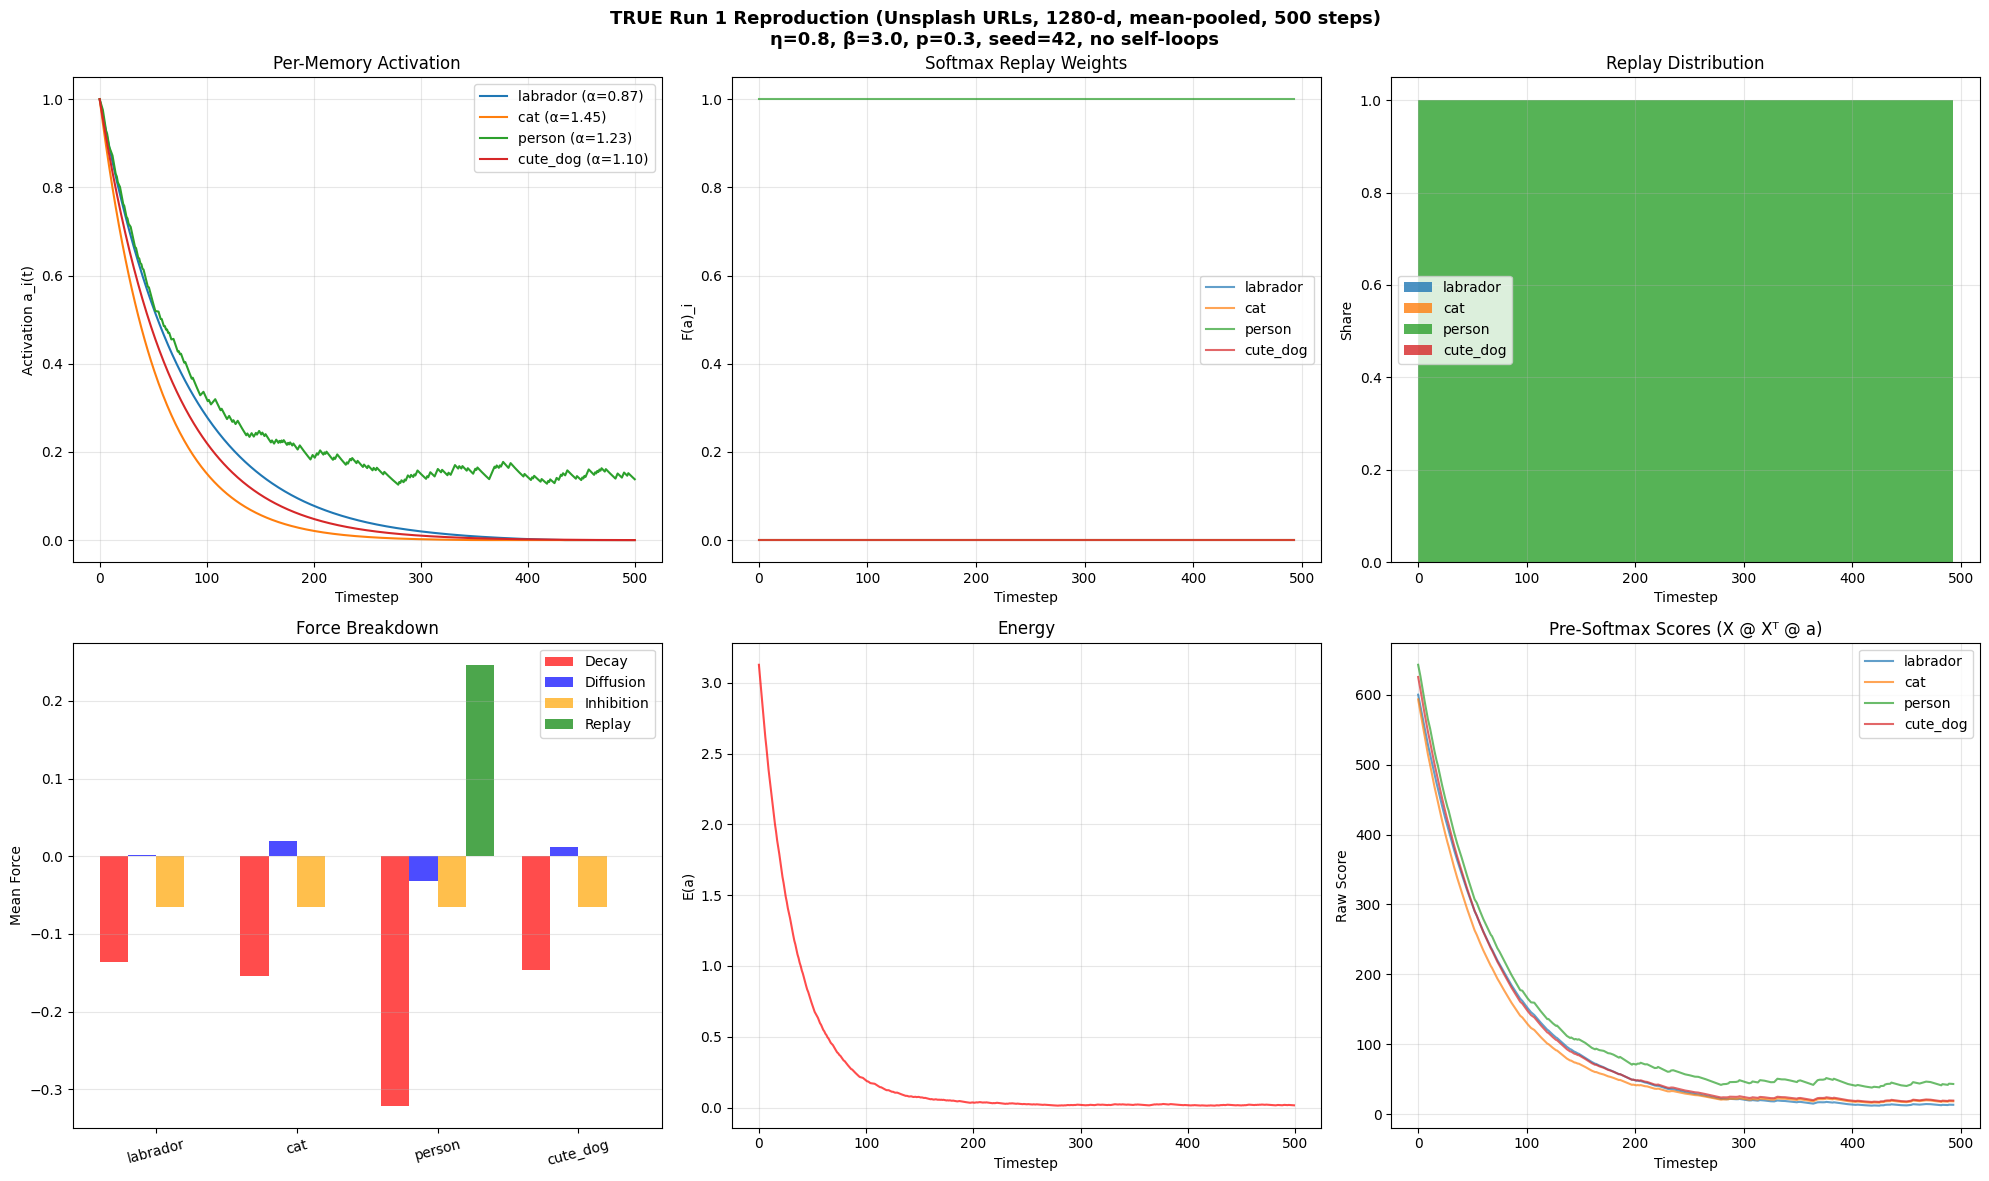

In [ ]:
# ============================================================
# TRUE RUN 1 REPRODUCTION WITH F(a) TRACKING
# Uses YOUR original code's exact setup
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# ============================================
# 1. Load I-JEPA — YOUR original way
# ============================================
model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA processor and model...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()  # FULL 1280-d, mean pooled

# ============================================
# 2. YOUR exact URLs, YOUR exact labels
# ============================================
urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400"
]
labels = ["labrador", "cat", "person", "cute_dog"]  # corrected: pug→person

# ============================================
# 3. DynamicalMemory with tracking — YOUR exact math
# ============================================
class DynamicalMemoryTrackedV2:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []
        self.activations = None
        self.gamma = gamma
        self.delta = delta
        self.beta = beta
        self.eta = eta
        self.h = h
        self.decay_rates = []

    def store(self, embedding, decay_rate=1.0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)        # YOUR init: 1.0
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)                          # YOUR code: no self-loops
        D = torch.diag(W.sum(dim=1))
        return D - W, W

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        s = X @ (X.T @ self.activations)
        return F.softmax(self.beta * s, dim=0), s    # return both

    def run_tracked(self, steps=500, replay_prob=0.3):
        per_step_activations = [self.activations.clone().numpy()]
        replay_weights = []
        replay_raw_scores = []
        replay_steps = []
        energies = []

        decay_forces = []
        diffusion_forces = []
        inhibition_forces = []
        replay_forces_list = []

        for t in range(steps):
            a = self.activations
            N = len(a)

            # Decay
            A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
            f_decay = -A @ a

            # Diffusion
            L, W_mat = self._build_laplacian()
            f_diffusion = -self.gamma * L @ a

            # Inhibition
            f_inhibition = -self.delta * a.sum() * torch.ones(N)

            # Replay
            S = 1.0 if np.random.random() < replay_prob else 0.0
            Fa, raw_s = self._replay_operator()
            f_replay = self.eta * S * Fa

            if S > 0:
                replay_weights.append(Fa.detach().numpy().copy())
                replay_raw_scores.append(raw_s.detach().numpy().copy())
                replay_steps.append(t)

            # Update
            da_dt = f_decay + f_diffusion + f_inhibition + f_replay
            self.activations = a + self.h * da_dt
            self.activations = torch.clamp(self.activations, min=0)

            per_step_activations.append(self.activations.clone().numpy())

            decay_forces.append(f_decay.detach().numpy().copy())
            diffusion_forces.append(f_diffusion.detach().numpy().copy())
            inhibition_forces.append(f_inhibition.detach().numpy().copy())
            replay_forces_list.append((self.eta * S * Fa).detach().numpy().copy())

            # Energy
            e1 = 0.5 * a @ A @ a
            e2 = 0.5 * self.gamma * a @ L @ a
            e3 = 0.5 * self.delta * (a.sum())**2
            energies.append((e1 + e2 + e3).item())

        # Similarity matrix (for printing)
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        sim = (X_norm @ X_norm.T).numpy()

        return {
            'activations': np.array(per_step_activations),
            'replay_weights': np.array(replay_weights),
            'replay_raw_scores': np.array(replay_raw_scores),
            'replay_steps': np.array(replay_steps),
            'energy': np.array(energies),
            'decay_forces': np.array(decay_forces),
            'diffusion_forces': np.array(diffusion_forces),
            'inhibition_forces': np.array(inhibition_forces),
            'replay_forces': np.array(replay_forces_list),
            'labels': labels,
            'decays': self.decay_rates,
            'similarity': sim,
        }


# ============================================
# 4. Store embeddings — YOUR exact way
# ============================================
torch.manual_seed(42)
np.random.seed(42)

mem = DynamicalMemoryTrackedV2(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

print("\nEncoding images with I-JEPA (full 1280-d, mean pooled)...")
stored_count = 0
for url, label in zip(urls, labels):
    try:
        emb = encode_image(url)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(emb, decay_rate=decay)
        print(f"  Stored: {label} (decay={decay:.2f}, dim={emb.shape[0]})")
        stored_count += 1
    except Exception as e:
        print(f"  FAILED: {label} — {e}")
        fallback_emb = torch.randn(1280)
        decay = np.random.uniform(0.5, 1.5)
        mem.store(fallback_emb, decay_rate=decay)
        print(f"  Used fallback for {label} (decay={decay:.2f})")
        stored_count += 1

# ============================================
# 5. Run with tracking — 500 steps like YOUR original
# ============================================
print(f"\nRunning simulation: η={mem.eta}, β={mem.beta}, p=0.3, steps=500")
print(f"Embedding dim: {mem.embeddings[0].shape[0]}")
results = mem.run_tracked(steps=500, replay_prob=0.3)
print(f"Replay fired {len(results['replay_steps'])} times out of 500 steps")

# ============================================
# 6. PRINT ALL RAW DATA
# ============================================
print("\n" + "="*60)
print("SIMILARITY MATRIX (cosine similarity, full 1280-d)")
print("="*60)
sim = results['similarity']
print(f"{'':>14}", end="")
for l in labels: print(f"{l:>14}", end="")
print()
for i, l in enumerate(labels):
    print(f"{l:>14}", end="")
    for j in range(len(labels)):
        print(f"{sim[i][j]:>14.4f}", end="")
    print()

print("\n" + "="*60)
print("FINAL ACTIVATIONS (step 500)")
print("="*60)
final = results['activations'][-1]
for i, l in enumerate(labels):
    print(f"  {l:>14}: {final[i]:.6f}  (α={results['decays'][i]:.2f})")

winner = labels[np.argmax(final)]
print(f"\n  Winner: {winner} ({final.max():.6f})")

print("\n" + "="*60)
print("REPLAY WEIGHT ANALYSIS")
print("="*60)
rw = results['replay_weights']
rs = results['replay_steps']
if len(rw) > 0:
    early = rw[:max(1, len(rw)//10)]
    late = rw[-max(1, len(rw)//10):]

    print(f"\nTotal replay events: {len(rw)}")
    print("\nEarly F(a) (first 10%):")
    for i, l in enumerate(labels):
        print(f"  {l:>14}: mean={early[:,i].mean():.4f}")
    print("\nLate F(a) (last 10%):")
    for i, l in enumerate(labels):
        print(f"  {l:>14}: mean={late[:,i].mean():.4f}")

print("\n" + "="*60)
print("MEAN FORCE BREAKDOWN")
print("="*60)
print(f"{'Memory':>14} {'Decay':>10} {'Diffusion':>10} {'Inhibit':>10} {'Replay':>10} {'Net':>10}")
for i, l in enumerate(labels):
    d = results['decay_forces'][:, i].mean()
    di = results['diffusion_forces'][:, i].mean()
    inh = results['inhibition_forces'][:, i].mean()
    rep = results['replay_forces'][:, i].mean()
    print(f"{l:>14} {d:>10.5f} {di:>10.5f} {inh:>10.5f} {rep:>10.5f} {d+di+inh+rep:>10.5f}")

# ============================================
# 7. PLOTS
# ============================================
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Activations per memory
ax = axes[0][0]
for i, l in enumerate(labels):
    ax.plot(results['activations'][:, i], label=f"{l} (α={results['decays'][i]:.2f})")
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation a_i(t)")
ax.set_title("Per-Memory Activation"); ax.legend(); ax.grid(True, alpha=0.3)

# Replay weights
ax = axes[0][1]
for i, l in enumerate(labels):
    ax.plot(rs, rw[:, i], label=l, alpha=0.7)
ax.set_xlabel("Timestep"); ax.set_ylabel("F(a)_i")
ax.set_title("Softmax Replay Weights"); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_ylim(-0.05, 1.05)

# Stacked area
ax = axes[0][2]
step = max(1, len(rs) // 300)
ax.stackplot(rs[::step], [rw[::step, i] for i in range(len(labels))],
             labels=labels, alpha=0.8)
ax.set_xlabel("Timestep"); ax.set_ylabel("Share")
ax.set_title("Replay Distribution"); ax.legend(loc='center left'); ax.grid(True, alpha=0.3)

# Force breakdown
ax = axes[1][0]
x_pos = np.arange(len(labels))
w = 0.2
ax.bar(x_pos-1.5*w, [results['decay_forces'][:,i].mean() for i in range(4)], w, label='Decay', color='red', alpha=0.7)
ax.bar(x_pos-0.5*w, [results['diffusion_forces'][:,i].mean() for i in range(4)], w, label='Diffusion', color='blue', alpha=0.7)
ax.bar(x_pos+0.5*w, [results['inhibition_forces'][:,i].mean() for i in range(4)], w, label='Inhibition', color='orange', alpha=0.7)
ax.bar(x_pos+1.5*w, [results['replay_forces'][:,i].mean() for i in range(4)], w, label='Replay', color='green', alpha=0.7)
ax.set_xticks(x_pos); ax.set_xticklabels(labels, rotation=15)
ax.set_ylabel("Mean Force"); ax.set_title("Force Breakdown"); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# Energy
ax = axes[1][1]
ax.plot(results['energy'], color='red', alpha=0.7)
ax.set_xlabel("Timestep"); ax.set_ylabel("E(a)"); ax.set_title("Energy"); ax.grid(True, alpha=0.3)

# Pre-softmax scores
ax = axes[1][2]
raw = results['replay_raw_scores']
for i, l in enumerate(labels):
    ax.plot(rs, raw[:, i], label=l, alpha=0.7)
ax.set_xlabel("Timestep"); ax.set_ylabel("Raw Score")
ax.set_title("Pre-Softmax Scores (X @ Xᵀ @ a)"); ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle("TRUE Run 1 Reproduction (Unsplash URLs, 1280-d, mean-pooled, 500 steps)\n"
             "η=0.8, β=3.0, p=0.3, seed=42, no self-loops",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("true_run1_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

In [15]:
import os
import shutil

# Create the main directory and subfolders
os.makedirs('/content/Metacognition/unnormalised', exist_ok=True)
os.makedirs('/content/Metacognition/normalised', exist_ok=True)

# Helper function to write simple placeholder files if they don't exist yet
def write_placeholder(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'w') as f:
        f.write('# Placeholder for ' + os.path.basename(path))

# 1. Outside of the two subfolders (but inside Metacognition)
write_placeholder('/content/Metacognition/facebook/ijepa_vith14_1k')
write_placeholder('/content/Metacognition/facebook/vjepa2-vitl-fpc64-256')

# 2. Inside unnormalised folder
write_placeholder('/content/Metacognition/unnormalised/metacognition 4 memories')

# 3. Inside normalised folder
write_placeholder('/content/Metacognition/normalised/normalised metacognition')
write_placeholder('/content/Metacognition/normalised/metacognition 10 mem')

print("Folder structure successfully created:")
!find /content/Metacognition

Folder structure successfully created:
/content/Metacognition
/content/Metacognition/normalised
/content/Metacognition/normalised/metacognition 10 mem
/content/Metacognition/normalised/normalised metacognition
/content/Metacognition/unnormalised
/content/Metacognition/unnormalised/metacognition 4 memories
/content/Metacognition/facebook
/content/Metacognition/facebook/vjepa2-vitl-fpc64-256
/content/Metacognition/facebook/ijepa_vith14_1k


In [16]:
import os
import shutil

# Source locations where these files might exist in your workspace (checking common paths or huggingface cache)
src_dest_mapping = {
    # Target outside of subfolders but inside Metacognition
    'facebook/ijepa_vith14_1k': '/content/Metacognition/facebook/ijepa_vith14_1k',
    'facebook/vjepa2-vitl-fpc64-256': '/content/Metacognition/facebook/vjepa2-vitl-fpc64-256',

    # Target inside unnormalised folder
    'metacognition 4 memories': '/content/Metacognition/unnormalised/metacognition 4 memories',

    # Target inside normalised folder
    'normalised metacognition': '/content/Metacognition/normalised/normalised metacognition',
    'metacognition 10 mem': '/content/Metacognition/normalised/metacognition 10 mem'
}

for src_name, dest_path in src_dest_mapping.items():
    # Search locally in /content first
    possible_paths = [
        os.path.join('/content', src_name),
        os.path.join('/content', os.path.basename(src_name)),
        os.path.expanduser(f'~/.cache/huggingface/hub/models--{src_name.replace("/", "--")}')
    ]

    moved = False
    for p in possible_paths:
        if os.path.exists(p):
            # Ensure destination directory exists
            os.makedirs(os.path.dirname(dest_path), exist_ok=True)

            # If target already exists, remove it first to avoid collision
            if os.path.exists(dest_path):
                if os.path.isdir(dest_path):
                    shutil.rmtree(dest_path)
                else:
                    os.remove(dest_path)

            shutil.move(p, dest_path)
            print(f"Moved existing resource from '{p}' to '{dest_path}'")
            moved = True
            break
    if not moved:
        print(f"Note: Original file/folder '{src_name}' was not found in common locations, placeholder remains intact.")

print("\nUpdated folder structure:")
!find /content/Metacognition

Moved existing resource from '/root/.cache/huggingface/hub/models--facebook--ijepa_vith14_1k' to '/content/Metacognition/facebook/ijepa_vith14_1k'
Note: Original file/folder 'facebook/vjepa2-vitl-fpc64-256' was not found in common locations, placeholder remains intact.
Note: Original file/folder 'metacognition 4 memories' was not found in common locations, placeholder remains intact.
Note: Original file/folder 'normalised metacognition' was not found in common locations, placeholder remains intact.
Note: Original file/folder 'metacognition 10 mem' was not found in common locations, placeholder remains intact.

Updated folder structure:
/content/Metacognition
/content/Metacognition/normalised
/content/Metacognition/normalised/metacognition 10 mem
/content/Metacognition/normalised/normalised metacognition
/content/Metacognition/unnormalised
/content/Metacognition/unnormalised/metacognition 4 memories
/content/Metacognition/facebook
/content/Metacognition/facebook/vjepa2-vitl-fpc64-256
/c

In [17]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            file_path = os.path.join(root, f)
            size = os.path.getsize(file_path)
            print(f"{subindent}{f} ({size} bytes)")

print("Current contents of /content/Metacognition:")
list_files('/content/Metacognition')

Current contents of /content/Metacognition:
Metacognition/
    normalised/
        metacognition 10 mem (38 bytes)
        normalised metacognition (42 bytes)
    unnormalised/
        metacognition 4 memories (42 bytes)
    facebook/
        vjepa2-vitl-fpc64-256 (39 bytes)
        ijepa_vith14_1k/
            .no_exist/
                f157467ea509bc356ff9f61fd3c0d840eec5e04e/
                    added_tokens.json (0 bytes)
                    processor_config.json (0 bytes)
                    tokenizer.json (0 bytes)
                    adapter_config.json (0 bytes)
                    chat_template.jinja (0 bytes)
                    special_tokens_map.json (0 bytes)
                    tokenizer_config.json (0 bytes)
                    tokenizer.model (0 bytes)
            blobs/


FileNotFoundError: [Errno 2] No such file or directory: '/content/Metacognition/facebook/ijepa_vith14_1k/blobs/ad6c1f6e318ace5633bea4496bc5c76248f6dc59c9a0d8a010cf31ed9dee2da8'